# 25. Leverage value re-measured with futures prices, mark-price liquidation and funding

In notebook 24 I judged liquidation on Binance **spot** one-minute lows, but USDⓈ-M perpetual futures are liquidated on the **mark price**, which combines prices from several exchanges; momentary spot wicks may therefore have inflated the liquidation count, and I left funding out. Here I re-measure the leverage value of the M0 alerts in the development period (2023-01 to 2026-04) with three changes:

1. I compute profit and loss on the **BTCUSDT perpetual futures close** (the futures cache from notebook 13) instead of the spot close.
2. I judge liquidation on the **mark-price one-minute low** (Binance public data `futures/um/monthly/markPriceKlines`) instead of the spot low.
3. I charge funding: when a settlement time falls inside the 4-hour holding window, the long pays notional × funding rate (funding cache from notebook 21).

I keep everything else as in notebook 24 and record it in `25_SPEC.json`: the 800 M0 calendar alerts, alert times and entry minute (notebook 15 rule), leverage of 1, 2, 5, 10, 20 and 50x, a maintenance margin rate of 0.5%, one-way fees of 0 and 5 bp, the random comparisons (alerts moved within the same volatility decile and ±30 days, or shifted circularly by at least 7 days; same random numbers), the month-block bootstrap and the reading rule (after a 5 bp fee, 95% lower bound > 0 and above regime-matched random times, p < 0.05). I report three variants side by side: `spot (nb24)`, which reproduces notebook 24 to the last digit, `futures + mark`, and `futures + mark + funding`, the main result. I exclude four-hour windows with a missing mark or futures price and count them. This calculation is exploratory and illustrative, and I do not use the holdouts. I write the results to `leverage_markprice_v1/`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

import concurrent.futures as cf

OUT = SPOT_BASE / 'leverage_markprice_v1'; OUT.mkdir(parents=True, exist_ok=True)
CAS = SPOT_BASE / 'causal_alert_selection_v1'; VAL15 = SPOT_BASE / 'detection_value_v1'; LV24 = SPOT_BASE / 'leverage_value_v1'
MARK_DIR = SPOT_BASE / 'cache' / 'futures_markprice'; MARK_DIR.mkdir(parents=True, exist_ok=True)
FUND_PQ = SPOT_BASE / 'cache' / 'futures_positioning' / 'BTCUSDT_um_funding.parquet'
FUT_PQ = FUT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet'
K_GRID = [1, 2, 5, 10, 20, 50]; MM = 0.005; HOLD = 240; FEES_BP = [0, 5]; MAX_WAIT = 5; RV_WINDOW = 1440
N_NULL = 1000; N_BOOT_M = 2000; SEED = 20261107; SHORT_BAND = (240, 1440)       # same seed as notebook 24
MARK_MONTHS = month_list('2023-01', '2026-04'); MIN_COVERAGE = 0.99
for _p in [CAS / 'alarms_first_eligible.csv', VAL15 / '2_net_value_by_fee.csv', LV24 / 'LEVERAGE_VALUE_SUMMARY.json', FUND_PQ, FUT_PQ]:
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05, 13, 15, 21 and 24 are required: {_p}')

VARIANTS = ['spot (nb24)', 'futures + mark', 'futures + mark + funding']
SPEC = {'title': 'Leverage value re-measured with futures prices, mark-price liquidation and funding (dev 2023-01..2026-04, exploratory)',
        'changes_vs_nb24': {'pnl': 'BTCUSDT perpetual 1m close (notebook-13 futures cache)',
                            'liquidation': 'mark-price 1m lows (data.binance.vision futures/um/monthly/markPriceKlines/BTCUSDT/1m, SHA-256 checked) '
                                           'over the 240 minutes after entry, against entry * (1 - 1/k) / (1 - mm) with entry = futures close',
                            'funding': 'a held long pays notional * funding rate at every funding time in (entry, entry + 240 min] (notebook-21 funding cache)'},
        'unchanged': 'M0 calendar alarms, entry minute (notebook-15 rule), leverage grid, mm, fees, nulls and seeds, month-block bootstrap, reading rule',
        'variants': VARIANTS, 'main_variant': VARIANTS[2],
        'missing_data': 'a 240-min window without a finite futures close at both ends and a finite mark low in every minute is dropped and counted',
        'leverage': K_GRID, 'maintenance_margin': MM, 'fees_bp_one_way': FEES_BP, 'null_draws': N_NULL, 'bootstrap': N_BOOT_M, 'seed': SEED,
        'reading_rule': 'For the main variant at leverage k the alert stream is said to pay if the 95% lower bound of the mean value per alert after a 5-bp fee '
                        'is > 0 and the observed mean exceeds the regime-matched null (p < 0.05). Reported for every k; no k is selected.',
        'holdouts': 'not used'}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '25_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'25_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/leverage_markprice_v1 | spec sha256 a9edc1bed1c2d395


## 1. Mark-price data

In [2]:
def fetch_mark(ym):
    url = f'{BINANCE}futures/um/monthly/markPriceKlines/BTCUSDT/1m/BTCUSDT-1m-{ym}.zip'; z = MARK_DIR / f'BTCUSDT-mark-1m-{ym}.zip'
    chk = _fetch(url + '.CHECKSUM')
    if chk is None:
        return dict(month=ym, url=url, sha256=None, status='not_listed')
    expected = chk.decode().split()[0].strip().lower()
    if z.is_file() and sha256_file(z) == expected:
        return dict(month=ym, url=url, sha256=expected, status='cached')
    data = _fetch(url)
    if data is None or hashlib.sha256(data).hexdigest() != expected:
        raise RuntimeError(f'mark-price archive missing or SHA-256 mismatch: {url}')
    part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
    return dict(month=ym, url=url, sha256=expected, status='downloaded')


def read_mark(path):
    """First five columns: open_time, open, high, low, close. Header row optional; ms or us timestamps."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, dtype=str, usecols=range(5))
    if not str(x.iloc[0, 0]).strip()[:1].isdigit():
        x = x.iloc[1:].reset_index(drop=True)
    x.columns = ['open_time', 'open', 'high', 'low', 'close']
    t = pd.to_numeric(x.open_time, errors='raise'); mag = float(t.abs().median())
    idx = pd.to_datetime(t, unit='us' if mag > 1e14 else ('ms' if mag > 1e11 else 's'), utc=True)
    z = x[['open', 'high', 'low', 'close']].apply(pd.to_numeric, errors='coerce'); z.index = pd.DatetimeIndex(idx, name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index()


t_ = time.time()
with cf.ThreadPoolExecutor(max_workers=8) as ex:
    MAN = pd.DataFrame(list(ex.map(fetch_mark, MARK_MONTHS)))
MAN.to_csv(OUT / '0_markprice_manifest.csv', index=False); print(MAN.status.value_counts().to_dict(), f'({time.time() - t_:.0f}s)')
if (MAN.status == 'not_listed').any():
    raise RuntimeError(f'mark-price archives not published for: {MAN[MAN.status == "not_listed"].month.tolist()}')
MARK = pd.concat([read_mark(MARK_DIR / f'BTCUSDT-mark-1m-{m}.zip') for m in MARK_MONTHS]).sort_index()
MARK = MARK[~MARK.index.duplicated(keep='last')]
print('mark price:', MARK.index.min(), '->', MARK.index.max(), f'{len(MARK):,} rows')

{'downloaded': 40} (9s)
mark price: 2023-01-01 00:00:00+00:00 -> 2026-04-30 23:59:00+00:00 1,749,598 rows


## 2. Data alignment, reproduction checks and diagnostics

In [3]:
px, _ = load_btc_spot()
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float); low = px.low.to_numpy(float)
good = np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0)
_idx = np.where(good, np.arange(len(T)), len(T)); NEXT_GOOD = np.minimum.accumulate(_idx[::-1])[::-1]
CF = pd.Series(close).ffill().to_numpy()
FWD_MIN = pd.Series(np.where(np.isfinite(low) & (low > 0), low, np.inf)).rolling(HOLD, min_periods=1).min().shift(-HOLD).to_numpy()
_lc = np.log(np.where(good, close, np.nan))
RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()

DEVM = in_period(T, EVAL_START, EVAL_END)
fut = pd.read_parquet(FUT_PQ, columns=['close']).sort_index(); fut.index = fut.index.tz_convert('UTC')
FUTC = fut.close.reindex(px.index).to_numpy(float); FUTC = np.where(FUTC > 0, FUTC, np.nan)
if np.isfinite(FUTC[DEVM]).mean() < MIN_COVERAGE:          # cache from notebook 13 too short: fetch the perpetual 1m klines for the dev months
    print(f'futures cache covers {np.isfinite(FUTC[DEVM]).mean():.3f} of the dev minutes; downloading BTCUSDT perpetual 1m klines')
    FUT_DIR = SPOT_BASE / 'cache' / 'futures_klines_nb25'
    _mf = get_archives('futures/um', 'BTCUSDT', MARK_MONTHS, FUT_DIR); _mf.to_csv(OUT / '0_futures_klines_manifest.csv', index=False)
    fut = regularize(load_archives(_mf, FUT_DIR))
    FUTC = fut.close.reindex(px.index).to_numpy(float); FUTC = np.where(FUTC > 0, FUTC, np.nan)
mk = MARK.reindex(px.index); MLOW = mk.low.to_numpy(float); MLOW = np.where(MLOW > 0, MLOW, np.nan); MCLOSE = mk.close.to_numpy(float)
_fin = np.isfinite(MLOW).astype(float)
MARK_FULL = (pd.Series(_fin).rolling(HOLD, min_periods=HOLD).sum().shift(-HOLD).to_numpy() == HOLD)        # every minute of (e, e+HOLD] observed
FWD_MLOW = pd.Series(np.where(np.isfinite(MLOW), MLOW, np.inf)).rolling(HOLD, min_periods=1).min().shift(-HOLD).to_numpy()

fund = pd.read_parquet(FUND_PQ).sort_index(); fund.index = pd.DatetimeIndex(fund.index).tz_convert('UTC')
fund = fund[np.isfinite(fund.funding_rate.to_numpy(float))]
FT = fund.index.asi8; FCUM = np.r_[0.0, np.cumsum(fund.funding_rate.to_numpy(float))]


def funding_sum(e):
    t0 = T[e]; lo = np.searchsorted(FT, t0, 'right'); hi = np.searchsorted(FT, t0 + HOLD * NS, 'right')
    return FCUM[hi] - FCUM[lo]


E = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
EV = events_between(E, EVAL_START, EVAL_END)
A0 = np.sort(pd.to_datetime(pd.read_csv(CAS / 'alarms_first_eligible.csv').alarm_utc, utc=True).astype('int64').to_numpy())
st0 = statistics(EV, A0)
if [st0['alarms'], st0['caught'], st0['before_1pct']] != REF['first_eligible']:
    raise RuntimeError('GUARD FAIL: M0 calendar alarms do not reproduce notebook 5')


def entry_idx(times):
    i0 = np.minimum(np.searchsorted(T, np.asarray(times, np.int64), 'right'), len(T) - 1); ie = NEXT_GOOD[i0]
    return np.where((ie < len(T)) & (ie - i0 < MAX_WAIT), ie, -1)


ie0 = entry_idx(A0); ok0 = (ie0 >= 0) & (ie0 + HOLD < len(T))
v15 = pd.read_csv(VAL15 / '2_net_value_by_fee.csv')
r15 = v15[(v15.policy == 'calendar') & (v15.period == 'dev') & (v15.subset == 'all alerts') & (v15.one_way_fee_bp == 0)].iloc[0]
_lv = -np.log(CF[ie0[ok0] + HOLD] / CF[ie0[ok0]])
if int(ok0.sum()) != int(r15.alerts) or abs(1e4 * _lv.mean() - float(r15.mean_net_per_alert_bp)) > 1e-6:
    raise RuntimeError('GUARD FAIL: M0 alert values differ from notebook 15')

cov = dict(futures_close=float(np.isfinite(FUTC[DEVM]).mean()), mark_low=float(np.isfinite(MLOW[DEVM]).mean()),
           funding_events=int(((FT >= ts(EVAL_START).value) & (FT < ts(EVAL_END).value)).sum()))
if cov['futures_close'] < MIN_COVERAGE or cov['mark_low'] < MIN_COVERAGE:
    raise RuntimeError(f'futures/mark-price coverage of the dev minutes below {MIN_COVERAGE}: {cov}')
both = DEVM & np.isfinite(MLOW) & np.isfinite(low) & (low > 0)
wick = MLOW[both] / low[both] - 1; basis = FUTC[DEVM & np.isfinite(FUTC) & good] / close[DEVM & np.isfinite(FUTC) & good] - 1
fr = fund.funding_rate[(fund.index >= ts(EVAL_START)) & (fund.index < ts(EVAL_END))]
DIAG = pd.DataFrame([dict(item='coverage: futures close (dev minutes)', value=cov['futures_close']),
                     dict(item='coverage: mark-price low (dev minutes)', value=cov['mark_low']),
                     dict(item='funding settlements in dev', value=cov['funding_events']),
                     dict(item='funding rate per settlement, mean (bp)', value=1e4 * float(fr.mean())),
                     dict(item='funding rate > 0, share of settlements', value=float((fr > 0).mean())),
                     *[dict(item=f'mark low / spot low - 1, quantile {q}', value=float(np.quantile(wick, q))) for q in [0.001, 0.01, 0.5, 0.99, 0.999]],
                     dict(item='minutes where the spot low is > 0.5% below the mark low, share', value=float((wick > 0.005 / 0.995).mean())),
                     *[dict(item=f'futures close / spot close - 1, quantile {q}', value=float(np.quantile(basis, q))) for q in [0.01, 0.5, 0.99]]])
DIAG.to_csv(OUT / '1_markprice_diagnostics.csv', index=False); display(DIAG)
print(f'{len(EV)} dev events; M0 alarms and spot values reproduce notebooks 5 and 15')

,item,value
0,coverage: futures close (dev minutes),1.000000
1,coverage: mark-price low (dev minutes),0.999176
2,funding settlements in dev,3648.000000
3,"funding rate per settlement, mean (bp)",0.687323
4,"funding rate > 0, share of settlements",0.862116
5,"mark low / spot low - 1, quantile 0.001",-0.000709
6,"mark low / spot low - 1, quantile 0.01",-0.000623
7,"mark low / spot low - 1, quantile 0.5",-0.000374
8,"mark low / spot low - 1, quantile 0.99",0.001007
9,"mark low / spot low - 1, quantile 0.999",0.001676


83 dev events; M0 alarms and spot values reproduce notebooks 5 and 15


## 3. Value of the three variants and the random comparison

In [4]:
def liq_return(k):
    return (1 - 1 / k) / (1 - MM) - 1


def window_terms(ie, variant):
    """Per alert: validity, entry price, end price, lowest liquidation-relevant price, funding sum."""
    ok = (ie >= 0) & (ie + HOLD < len(T)); e = np.where(ok, ie, 0)
    if variant == VARIANTS[0]:
        return ok, CF[e], CF[np.minimum(e + HOLD, len(T) - 1)], FWD_MIN[e], np.zeros(len(e))
    p0 = FUTC[e]; p1 = FUTC[np.minimum(e + HOLD, len(T) - 1)]
    valid = ok & np.isfinite(p0) & np.isfinite(p1) & MARK_FULL[e]
    fsum = funding_sum(e) if variant == VARIANTS[2] else np.zeros(len(e))
    return valid, p0, p1, FWD_MLOW[e], fsum


def values_and_liq(ie, k, fee_bp, variant):
    valid, p0, p1, pmin, fsum = window_terms(ie, variant)
    liq = (pmin / p0 - 1) <= liq_return(k)
    held = np.where(liq, -100.0, 100.0 * k * (p1 / p0 - 1) - 100.0 * k * fsum)
    v = -held - 2 * fee_bp * 1e-4 * k * 100
    return np.where(valid, v, np.nan), np.where(valid, liq, False), valid


def make_draw_space(start, end):
    okd = in_period(T, start, end) & np.isfinite(RV)
    tt = T[okd]; dq = np.minimum((pd.Series(RV[okd]).rank(pct=True).to_numpy() * 10).astype(int), 9)
    o = np.lexsort((tt, dq)); ds = dq[o]
    return dict(t0=ts(start).value, L=(ts(end).value - ts(start).value) // NS, TT=tt, DD=dq, PP=tt[o],
                STARTS=np.searchsorted(ds, np.arange(10), 'left'), ENDS=np.searchsorted(ds, np.arange(10), 'right'))


def draw_circular(a, rng, sp):
    d = int(rng.integers(7 * 1440, sp['L'] - 7 * 1440))
    return np.sort(sp['t0'] + (a - sp['t0'] + d * NS) % (sp['L'] * NS))


def draw_regime(a, rng, sp, W=30 * 1440 * NS):
    TT_, PP_, STARTS_, ENDS_ = sp['TT'], sp['PP'], sp['STARTS'], sp['ENDS']
    j = np.clip(np.searchsorted(TT_, a, 'right') - 1, 0, len(TT_) - 1); ad = sp['DD'][j]
    lo = np.array([STARTS_[q] + np.searchsorted(PP_[STARTS_[q]:ENDS_[q]], ti - W, 'left') for ti, q in zip(a, ad)])
    hi = np.array([STARTS_[q] + np.searchsorted(PP_[STARTS_[q]:ENDS_[q]], ti + W, 'right') for ti, q in zip(a, ad)])
    c = PP_[lo + (rng.random(len(a)) * (hi - lo)).astype(np.int64)]; bad = np.abs(c - a) < LEAD_MAX * NS
    for _ in range(20):
        if not bad.any():
            break
        c[bad] = PP_[lo[bad] + (rng.random(int(bad.sum())) * (hi[bad] - lo[bad])).astype(np.int64)]; bad = np.abs(c - a) < LEAD_MAX * NS
    return np.sort(c)


DSP = make_draw_space(EVAL_START, EVAL_END)
NULL = {}; t_ = time.time()
for ni, (nname, drawer) in enumerate([('regime', draw_regime), ('circular', draw_circular)]):
    rng = np.random.default_rng(SEED + ni)
    m = {(var, k, f): np.empty(N_NULL) for var in VARIANTS for k in K_GRID for f in FEES_BP}; lq = {(var, k): np.empty(N_NULL) for var in VARIANTS for k in K_GRID}
    for i in range(N_NULL):
        ie = entry_idx(drawer(A0, rng, DSP))
        for var in VARIANTS:
            for k in K_GRID:
                for f in FEES_BP:
                    v, l_, val = values_and_liq(ie, k, f, var); m[(var, k, f)][i] = np.nanmean(v)
                lq[(var, k)][i] = l_[val].mean()
    NULL[nname] = (m, lq); print(f'{nname}: {N_NULL} draws ({time.time() - t_:.0f}s)', flush=True)

m0 = match_events(EV, A0); HIT = np.isin(A0, m0.alarm_utc.astype('int64').to_numpy())
MONTH = (pd.to_datetime(A0, utc=True).year.to_numpy() * 12 + pd.to_datetime(A0, utc=True).month.to_numpy())
UM = np.unique(MONTH); rngb = np.random.default_rng(SEED + 99); PICKS = rngb.integers(0, len(UM), (N_BOOT_M, len(UM)))
rows = []
for var in VARIANTS:
    for k in K_GRID:
        v0, lq0, val0 = values_and_liq(ie0, k, 0, var)
        row = dict(variant=var, leverage=k, liquidation_move_pct=100 * liq_return(k), alerts=int(val0.sum()), alerts_dropped=int(ok0.sum() - val0.sum()),
                   hits=int((HIT & val0).sum()), liquidated_if_held=float(lq0[val0].mean()),
                   liquidated_if_held_hits=float(lq0[val0 & HIT].mean()) if (val0 & HIT).any() else np.nan,
                   liquidated_null_regime=float(NULL['regime'][1][(var, k)].mean()))
        for f in FEES_BP:
            v, _, val = values_and_liq(ie0, k, f, var)
            msum = np.array([np.nansum(v[val & (MONTH == u)]) for u in UM]); mcnt = np.array([int((val & (MONTH == u)).sum()) for u in UM])
            b = msum[PICKS].sum(axis=1) / np.maximum(mcnt[PICKS].sum(axis=1), 1)
            row[f'value_per_alert_fee{f}'] = float(np.nanmean(v[val]))
            row[f'value_per_alert_fee{f}_lo'], row[f'value_per_alert_fee{f}_hi'] = (float(x) for x in np.percentile(b, [2.5, 97.5]))
            for nname in NULL:
                nm = NULL[nname][0][(var, k, f)]
                row[f'null_{nname}_fee{f}'] = float(nm.mean()); row[f'p_{nname}_fee{f}'] = (1 + int((nm >= np.nanmean(v[val])).sum())) / (N_NULL + 1)
        L_ = float(np.nanmean(v0[val0 & HIT])) if (val0 & HIT).any() else np.nan; C_ = -float(np.nanmean(v0[val0 & ~HIT]))
        row.update(value_hit_fee0=L_, value_nonhit_fee0=-C_, p_star_fee0=(0.0 if C_ <= 0 else C_ / (C_ + L_)) if np.isfinite(L_) and C_ + L_ > 0 else np.nan,
                   hit_share=float(HIT[val0].mean()), break_even_fee_bp=row['value_per_alert_fee0'] / (2 * 1e-4 * k * 100))
        row['pays_by_rule'] = bool(row['value_per_alert_fee5_lo'] > 0 and row['p_regime_fee5'] < 0.05)
        rows.append(row)
LV = pd.DataFrame(rows)

# guard: the spot variant must equal notebook 24 to the last digit
s24 = pd.DataFrame(json.loads((LV24 / 'LEVERAGE_VALUE_SUMMARY.json').read_text())['leverage_value']).set_index('leverage')
_sv = LV[LV.variant == VARIANTS[0]].set_index('leverage')
for c_ in ['liquidated_if_held', 'liquidated_null_regime', 'value_per_alert_fee0', 'value_per_alert_fee5', 'value_per_alert_fee5_lo', 'null_regime_fee5', 'p_regime_fee5']:
    if not np.allclose(_sv[c_].to_numpy(float), s24.loc[_sv.index, c_].to_numpy(float), rtol=0, atol=1e-9, equal_nan=True):
        raise RuntimeError(f'GUARD FAIL: spot variant differs from notebook 24 in {c_}')
print('PASS: spot variant reproduces notebook 24')

_flip = []
for k in K_GRID:
    _, ls_, vs_ = values_and_liq(ie0, k, 0, VARIANTS[0]); _, lm_, vm_ = values_and_liq(ie0, k, 0, VARIANTS[1]); both_ = vs_ & vm_
    _flip.append(dict(leverage=k, alerts_compared=int(both_.sum()), liquidated_spot_only=int((ls_ & ~lm_ & both_).sum()),
                      liquidated_mark_only=int((lm_ & ~ls_ & both_).sum()), liquidated_both=int((ls_ & lm_ & both_).sum())))
FLIP = pd.DataFrame(_flip); FLIP.to_csv(OUT / '2_liquidation_spot_vs_mark.csv', index=False); display(FLIP)
LV.to_csv(OUT / '2_leverage_value_by_variant.csv', index=False)
display(LV.pivot(index='leverage', columns='variant', values='liquidated_if_held').round(4))
display(LV.pivot(index='leverage', columns='variant', values='value_per_alert_fee5').round(3))
display(LV[LV.variant == VARIANTS[2]][['leverage', 'alerts', 'alerts_dropped', 'liquidated_if_held', 'liquidated_null_regime', 'value_per_alert_fee0', 'value_per_alert_fee0_lo',
                                       'value_per_alert_fee0_hi', 'value_per_alert_fee5', 'value_per_alert_fee5_lo', 'value_per_alert_fee5_hi', 'null_regime_fee5',
                                       'p_regime_fee5', 'p_star_fee0', 'break_even_fee_bp', 'pays_by_rule']].round(3))

regime: 1000 draws (16s)
circular: 1000 draws (23s)
PASS: spot variant reproduces notebook 24


,leverage,alerts_compared,liquidated_spot_only,liquidated_mark_only,liquidated_both
0,1,800,0,0,0
1,2,800,0,0,0
2,5,800,0,0,0
3,10,800,1,0,2
4,20,800,0,0,27
5,50,800,7,0,205


variant,futures + mark,futures + mark + funding,spot (nb24)
leverage,,,
1,0.0000,0.0000,0.0000
2,0.0000,0.0000,0.0000
5,0.0000,0.0000,0.0000
10,0.0025,0.0025,0.0038
20,0.0338,0.0338,0.0338
50,0.2562,0.2562,0.2650


variant,futures + mark,futures + mark + funding,spot (nb24)
leverage,,,
1,-0.053,-0.048,-0.055
2,-0.106,-0.097,-0.111
5,-0.265,-0.242,-0.277
10,-0.372,-0.327,-0.343
20,-0.076,0.008,-0.114
50,2.578,2.742,2.970


,leverage,alerts,alerts_dropped,liquidated_if_held,liquidated_null_regime,value_per_alert_fee0,value_per_alert_fee0_lo,value_per_alert_fee0_hi,value_per_alert_fee5,value_per_alert_fee5_lo,value_per_alert_fee5_hi,null_regime_fee5,p_regime_fee5,p_star_fee0,break_even_fee_bp,pays_by_rule
12,1,800,0,0.000,0.000,0.052,-0.037,0.138,-0.048,-0.137,0.038,-0.129,0.014,0.032,2.579,False
13,2,800,0,0.000,0.000,0.103,-0.075,0.276,-0.097,-0.275,0.076,-0.258,0.014,0.032,2.579,False
14,5,800,0,0.000,0.000,0.258,-0.187,0.691,-0.242,-0.687,0.191,-0.646,0.014,0.032,2.579,False
15,10,800,0,0.002,0.001,0.673,-0.289,1.617,-0.327,-1.289,0.617,-1.265,0.007,0.028,3.364,False
16,20,800,0,0.034,0.008,2.008,-0.002,4.013,0.008,-2.002,2.013,-2.400,0.002,0.020,5.021,False
17,50,800,0,0.256,0.128,7.742,2.884,12.331,2.742,-2.116,7.331,-2.923,0.002,0.000,7.742,False


## 4. Figures and summary

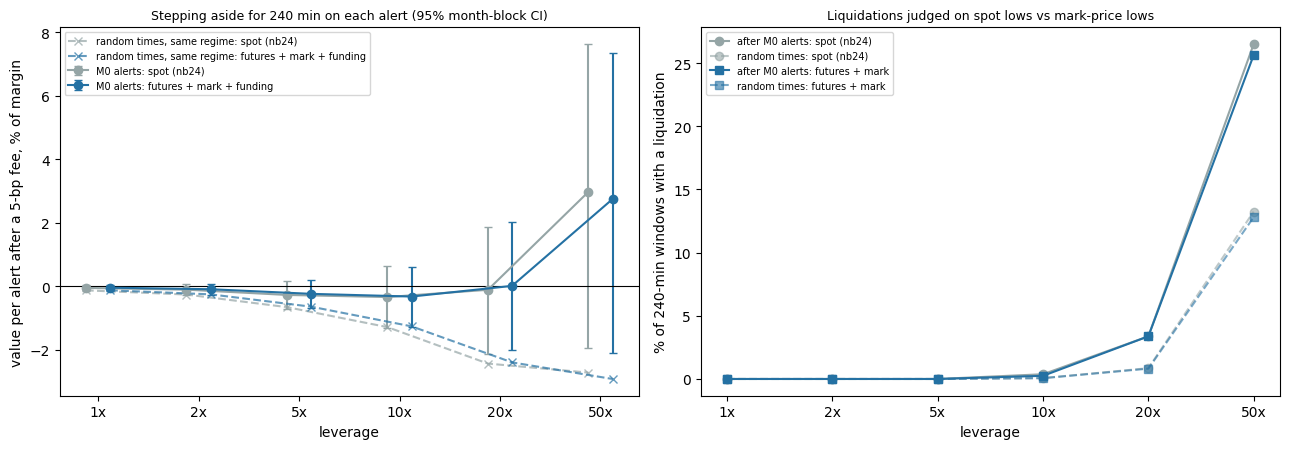

  1x | liquidated if held: alerts   0.0% vs random   0.0% (spot-based   0.0% vs   0.0%) | per alert, % of margin: fee0   +0.05, fee5   -0.05 [-0.14, +0.04] vs random   -0.13 (p 0.014) | break-even fee +2.6 bp | pays by rule: False
  2x | liquidated if held: alerts   0.0% vs random   0.0% (spot-based   0.0% vs   0.0%) | per alert, % of margin: fee0   +0.10, fee5   -0.10 [-0.27, +0.08] vs random   -0.26 (p 0.014) | break-even fee +2.6 bp | pays by rule: False
  5x | liquidated if held: alerts   0.0% vs random   0.0% (spot-based   0.0% vs   0.0%) | per alert, % of margin: fee0   +0.26, fee5   -0.24 [-0.69, +0.19] vs random   -0.65 (p 0.014) | break-even fee +2.6 bp | pays by rule: False
 10x | liquidated if held: alerts   0.2% vs random   0.1% (spot-based   0.4% vs   0.1%) | per alert, % of margin: fee0   +0.67, fee5   -0.33 [-1.29, +0.62] vs random   -1.27 (p 0.007) | break-even fee +3.4 bp | pays by rule: False
 20x | liquidated if held: alerts   3.4% vs random   0.8% (spot-based   3.4%

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); x = np.arange(len(K_GRID))
ax = axes[0]
for var, col, off in [(VARIANTS[0], '#95a5a6', -0.12), (VARIANTS[2], '#2471a3', 0.12)]:
    g = LV[LV.variant == var].set_index('leverage').loc[K_GRID]; y = g.value_per_alert_fee5
    ax.errorbar(x + off, y, yerr=[y - g.value_per_alert_fee5_lo, g.value_per_alert_fee5_hi - y], fmt='o-', color=col, capsize=3, label=f'M0 alerts: {var}')
    ax.plot(x + off, g.null_regime_fee5, 'x--', color=col, alpha=0.7, label=f'random times, same regime: {var}')
ax.axhline(0, color='k', lw=0.8); ax.set_xticks(x); ax.set_xticklabels([f'{k}x' for k in K_GRID]); ax.set_xlabel('leverage')
ax.set_ylabel('value per alert after a 5-bp fee, % of margin'); ax.set_title('Stepping aside for 240 min on each alert (95% month-block CI)', fontsize=9)
ax.legend(fontsize=7)
ax = axes[1]
for var, col, mk_ in [(VARIANTS[0], '#95a5a6', 'o'), (VARIANTS[1], '#2471a3', 's')]:
    g = LV[LV.variant == var].set_index('leverage').loc[K_GRID]
    ax.plot(x, 100 * g.liquidated_if_held, mk_ + '-', color=col, label=f'after M0 alerts: {var}')
    ax.plot(x, 100 * g.liquidated_null_regime, mk_ + '--', color=col, alpha=0.6, label=f'random times: {var}')
ax.set_xticks(x); ax.set_xticklabels([f'{k}x' for k in K_GRID]); ax.set_xlabel('leverage'); ax.set_ylabel('% of 240-min windows with a liquidation')
ax.set_title('Liquidations judged on spot lows vs mark-price lows', fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / '3_leverage_markprice.png', dpi=140); plt.show()

summary = dict(spec_sha256=SPEC_SHA, status='exploratory; dev 2023-01..2026-04 only; stylized margin model', reading_rule=SPEC['reading_rule'],
               diagnostics=DIAG.to_dict('records'), liquidation_spot_vs_mark=FLIP.to_dict('records'), leverage_value=LV.to_dict('records'))
(OUT / 'FUTURES_LEVERAGE_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))
for r in LV[LV.variant == VARIANTS[2]].itertuples():
    s_ = LV[(LV.variant == VARIANTS[0]) & (LV.leverage == r.leverage)].iloc[0]
    print(f"{r.leverage:3d}x | liquidated if held: alerts {100 * r.liquidated_if_held:5.1f}% vs random {100 * r.liquidated_null_regime:5.1f}% "
          f"(spot-based {100 * s_.liquidated_if_held:5.1f}% vs {100 * s_.liquidated_null_regime:5.1f}%) | per alert, % of margin: fee0 {r.value_per_alert_fee0:+7.2f}, "
          f"fee5 {r.value_per_alert_fee5:+7.2f} [{r.value_per_alert_fee5_lo:+.2f}, {r.value_per_alert_fee5_hi:+.2f}] vs random {r.null_regime_fee5:+7.2f} "
          f"(p {r.p_regime_fee5:.3f}) | break-even fee {r.break_even_fee_bp:+.1f} bp | pays by rule: {r.pays_by_rule}")

## Interpretation
- The main result is the `futures + mark + funding` row, which I read with the same rule as in notebook 24 (after a 5 bp fee, 95% lower bound > 0 and above random times).
- `2_liquidation_spot_vs_mark.csv` counts alerts liquidated on the spot low but not on the mark price. A large count means that spot wicks overstated the notebook 24 liquidations.
- When funding is mostly positive, a long holder pays a cost just for holding, so stepping aside becomes slightly more favorable. A 4-hour window contains zero or one settlement.
- The 0.5% maintenance margin rate is illustrative; actual exchanges tier it by position size. I ignore slippage, so this is an illustrative calculation.